# Etapa 3 — Modelagem

Entrada: `../data/processed/dataset.csv`, da Etapa 2.
Saída: um classificador treinado, avaliado e interpretado, e um ranking dos
melhores horários da janela.

Um detalhe que define esta etapa: **não existe label pronta.** O site
classifica as condições para pesca, não para surf — e pesca gosta de mar
calmo, quase o oposto. Definir o que é uma condição boa para surfar é a
primeira tarefa aqui, e é uma decisão sua.

In [1]:
from pathlib import Path

DIR_PROC = Path("..") / "data" / "processed"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Carregar o dataset processado

Confira que veio o que você espera: número de linhas, tipos, nulos. Se a
Etapa 2 mudou, isso aparece aqui.

In [2]:
df = pd.read_csv(DIR_PROC / "dataset.csv", parse_dates=["datetime"])

print(df.shape)
print(df.dtypes)
print("nulos:", df.isna().sum().sum())
df.head()

(168, 11)
onda_m                float64
onda_dir                  str
datetime       datetime64[us]
vento_kmh             float64
vento_dir                 str
mare_m                float64
mare_fase                 str
hora                    int64
dia_semana                str
periodo                   str
coeficiente             int64
dtype: object
nulos: 0


,onda_m,onda_dir,datetime,vento_kmh,vento_dir,mare_m,mare_fase,hora,dia_semana,periodo,coeficiente
0,1.0,ESE,2026-10-09 00:00:00,23.0,SE,1.500538,subindo,0,Friday,madrugada,95
1,1.0,ESE,2026-10-09 01:00:00,22.0,SE,1.855376,subindo,1,Friday,madrugada,95
2,1.0,ESE,2026-10-09 02:00:00,23.0,SE,2.210215,subindo,2,Friday,madrugada,95
3,1.0,ESE,2026-10-09 03:00:00,24.0,SE,2.434946,descendo,3,Friday,madrugada,95
4,1.0,ESE,2026-10-09 04:00:00,24.0,ESE,2.080108,descendo,4,Friday,madrugada,95


## 2. Definir a label

Escreva, em código, a regra que separa condições ruins, boas e ótimas (ou
outro conjunto de classes, se preferir).

- Quais variáveis entram na regra: altura da onda, vento, maré, direção?
- Quais limiares? De onde vem o número — leitura, conversa com surfista,
  distribuição dos próprios dados? Registre a origem, mesmo que seja um chute
  informado.
- Como as classes ficaram distribuídas? Se 95% das horas caírem numa classe,
  a métrica do modelo vai mentir para você.

Documente a regra em markdown antes de seguir. Tudo depois disso depende dela.

In [3]:
condicoes = [
    (df["onda_m"] >= 1.3) & (df["vento_kmh"] <= 22),
    (df["onda_m"] >= 1.2) & (df["vento_kmh"] <= 25),
]
df["label"] = np.select(condicoes, ["ótima", "boa"], default="ruim")

print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(2))

label
ruim     85
boa      48
ótima    35
Name: count, dtype: int64
label
ruim     0.51
boa      0.29
ótima    0.21
Name: proportion, dtype: float64


label     ruim  boa  ótima
datetime                  
09/10       24    0      0
10/10       24    0      0
11/10       24    0      0
12/10        1   22      1
13/10        9   10      5
14/10        3    5     16
15/10        0   11     13


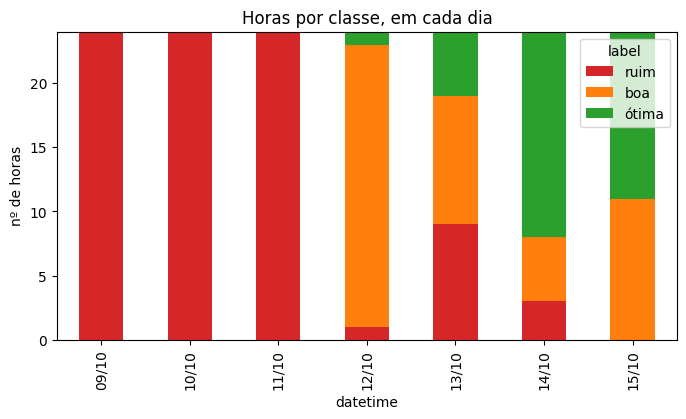

In [4]:
dia = df["datetime"].dt.strftime("%d/%m")
tabela = pd.crosstab(dia, df["label"])[["ruim", "boa", "ótima"]]
print(tabela)

tabela.plot(kind="bar", stacked=True, figsize=(8, 4), color=["tab:red", "tab:orange", "tab:green"])
plt.title("Horas por classe, em cada dia")
plt.ylabel("nº de horas")
plt.show()

1. Classifiquei as horas em três classes, usando só a altura da onda e a velocidade do vento, onda ≥ 1,3 m e vento ≤ 22 km/h sendo classificado como ótima, onda ≥ 1,2 m e vento ≤ 25 km/h, não entrando em ótima sendo classificada como boa e o restante entra na classificação de ruim.

2. Escolhi os limiares olhando os próprios dados da semana: a onda vai de 0,9 a 1,4 m e o vento tem mediana de 23 km/h, então usei 1,3 e 1,2 m para a onda e 22 e 25 km/h para o vento. Fiz uma breve pesquisa e tive a ideia de que ondas maiores e ventos mais fracos são melhores para surfar. Deixei de fora a direção, porque todo o vento da semana vem do mar e a onda é sempre de E ou ESE e a maré, porque não achei relação dela com a onda.

3. 85 horas ruins, 48 boas e 35 ótimas, mas nenhuma classe chega a dominar tanto quanto é dito na questão que poderia fazer o modelo mentir, se apenas uma classe chegasse a 95%

## 3. Features e alvo

Separe `X` e `y`.

- Quais colunas entram como feature? Cuidado: usar diretamente as variáveis da
  sua regra faz o modelo apenas redescobrir o `if` que você escreveu. Isso é
  esperado aqui — mas você precisa saber que é isso que está acontecendo.
- Direção do vento e da onda são texto. Como transformar em número sem inventar
  uma ordem que não existe?

In [5]:
colunas_num = ["onda_m", "vento_kmh", "mare_m", "hora"]
colunas_cat = ["onda_dir", "vento_dir", "mare_fase"]

X = pd.get_dummies(df[colunas_num + colunas_cat], columns=colunas_cat)
y = df["label"]

print(X.shape)
print(list(X.columns))

(168, 11)
['onda_m', 'vento_kmh', 'mare_m', 'hora', 'onda_dir_E', 'onda_dir_ESE', 'vento_dir_E', 'vento_dir_ESE', 'vento_dir_SE', 'mare_fase_descendo', 'mare_fase_subindo']


1. Usei como features onda_m, vento_kmh, mare_m, hora, onda_dir_E, onda_dir_ESE, vento_dir_E, vento_dir_ESE, vento_dir_SE, mare_fase_descendo e mare_fase_subindo. Como onda_m e vento_kmh são as variáveis da minha regra, o modelo vai só redescobrir o if que eu escrevi, e eu sei que é isso que está acontecendo. Deixei o coeficiente de fora porque ele tem o mesmo valor o dia inteiro e serviria só para o modelo adivinhar o dia.

2. Criei uma coluna para cada direção, com valor 0 ou 1, por exemplo, o vento virou três colunas (vento_dir_E, vento_dir_ESE e vento_dir_SE), e em cada hora só uma delas vale 1. Não usei 1, 2 e 3, porque o modelo acharia que existe uma ordem entre as direções, como se SE fosse maior que E, com o 0 ou 1, nenhuma direção vale mais que a outra. Fiz o mesmo com a direção da onda e com o sentido da maré.

## 4. Treino e teste

Divida os dados. Vale estratificar pelas classes? A ordem temporal importa —
sortear linhas de um mesmo dia entre treino e teste vaza informação?

In [6]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
print(len(X_treino), len(X_teste))
print(y_teste.value_counts())

117 51
label
ruim     26
boa      14
ótima    11
Name: count, dtype: int64


1. Dividi em 117 linhas para treino e 51 para teste, dividindo pela classe para manter a proporção (26 ruim, 14 boa e 11 ótima no teste). Sim, horas vizinhas do mesmo dia são quase iguais, então sortear linhas põe quase-cópias no treino e no teste e infla a acurácia.

## 5. Treinar

Treine pelo menos dois modelos de famílias diferentes (por exemplo uma árvore
e um modelo baseado em distância) para ter com o que comparar.

In [7]:
from sklearn.tree import DecisionTreeClassifier

arvore = DecisionTreeClassifier(max_depth=4, random_state=42)
arvore.fit(X_treino, y_treino)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['boa','ruim','ótima']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['onda_m','vento_kmh','mare_m',...,'vento_dir_SE','mare_fase_descendo', 'mare_fase_subindo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 6. Avaliar

- Acurácia é suficiente aqui, com as classes desbalanceadas como estão?
- Olhe a matriz de confusão: que erro o modelo comete?
- Um único split é confiável com poucas linhas, ou vale validação cruzada?

In [15]:
from sklearn.metrics import accuracy_score, classification_report

ordem = ["ruim", "boa", "ótima"]
for nome, modelo in [("Árvore", arvore), ("KNN", knn)]:
    print(nome, "- acurácia:", round(accuracy_score(y_teste, modelo.predict(X_teste)), 3))

print(classification_report(y_teste, arvore.predict(X_teste), labels=ordem, zero_division=0))

Árvore - acurácia: 1.0
KNN - acurácia: 0.706
              precision    recall  f1-score   support

        ruim       1.00      1.00      1.00        26
         boa       1.00      1.00      1.00        14
       ótima       1.00      1.00      1.00        11

    accuracy                           1.00        51
   macro avg       1.00      1.00      1.00        51
weighted avg       1.00      1.00      1.00        51



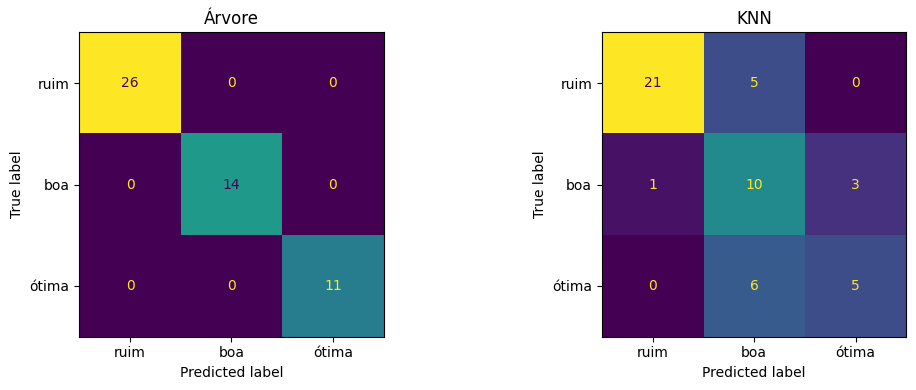

Árvore - acurácia deixando um dia de fora: 0.982
KNN - acurácia deixando um dia de fora: 0.762


In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nome, modelo) in zip(ax, [("Árvore", arvore), ("KNN", knn)]):
    ConfusionMatrixDisplay.from_estimator(modelo, X_teste, y_teste, labels=ordem, ax=a, colorbar=False)
    a.set_title(nome)
plt.tight_layout()
plt.show()

dia = df["datetime"].dt.date
for nome, modelo in [("Árvore", DecisionTreeClassifier(max_depth=4, random_state=42)),
                     ("KNN", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)))]:
    pred = cross_val_predict(modelo, X, y, groups=dia, cv=LeaveOneGroupOut())
    print(nome, "- acurácia deixando um dia de fora:", round(accuracy_score(y, pred), 3))

1. Não. O teste tem só 51 linhas e apenas 11 são ótima, então chutar sempre ruim já acertaria 51%, então os 70,6% do KNN não são muito melhores que isso e a acurácia não mostra onde o modelo erra, o KNN acerta só 5 das 11 horas ótimas, que são as que mais importam.

2. A árvore não errou nenhuma hora do teste, o KNN errou 15 de 51, sempre entre classes vizinhas, e nunca trocou ruim por ótima, o erro mais comum é chamar de boa uma hora que era ótima.

3. Não, com poucas linhas, o resultado muda conforme o sorteio, e as horas de um mesmo dia são muito parecidas, por isso também testei deixando um dia inteiro de fora, uma vez para cada dia. Assim, a árvore ficou em 98,2% (e não 100%) e o KNN em 76,2% (e não 70,6%). Os números mudam, então uma divisão apenas não é o suficiente.

## 7. Interpretar

Um modelo que acerta e você não sabe por quê não serve para responder nada.

- Plote a árvore. Os cortes que ela encontrou parecem com os seus limiares?
- Quais features o modelo considera mais importantes? Bate com sua intuição?
- Se a acurácia veio altíssima, explique o motivo — não celebre.

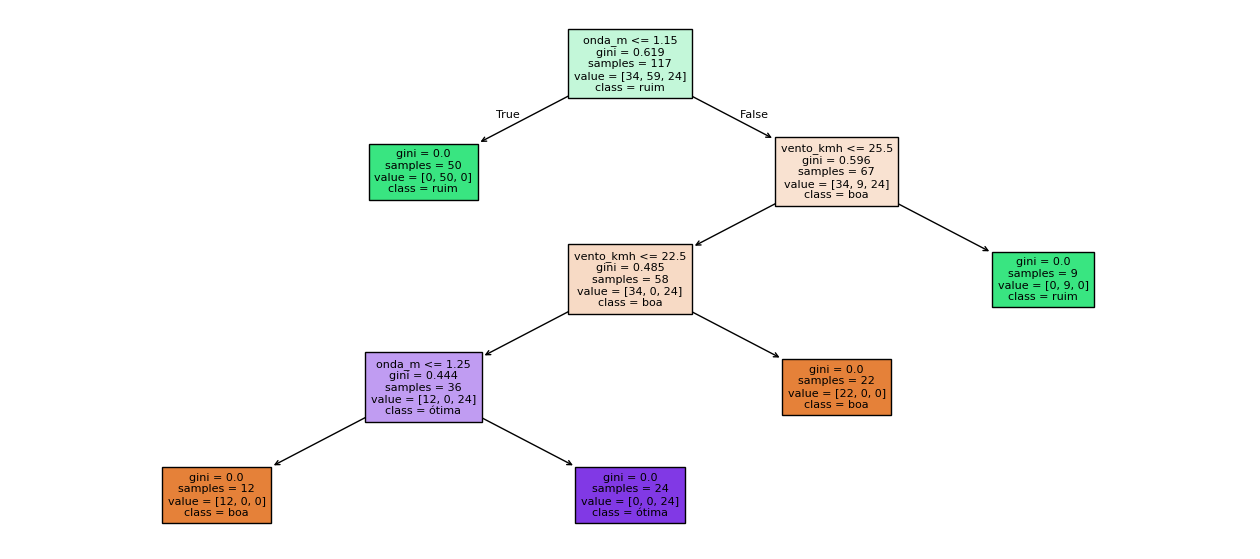

In [11]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 7))
plot_tree(arvore, feature_names=list(X.columns), class_names=list(arvore.classes_),
          filled=True, fontsize=8)
plt.show()

onda_m                0.67
vento_kmh             0.33
mare_m                0.00
hora                  0.00
onda_dir_E            0.00
onda_dir_ESE          0.00
vento_dir_E           0.00
vento_dir_ESE         0.00
vento_dir_SE          0.00
mare_fase_descendo    0.00
mare_fase_subindo     0.00
dtype: float64


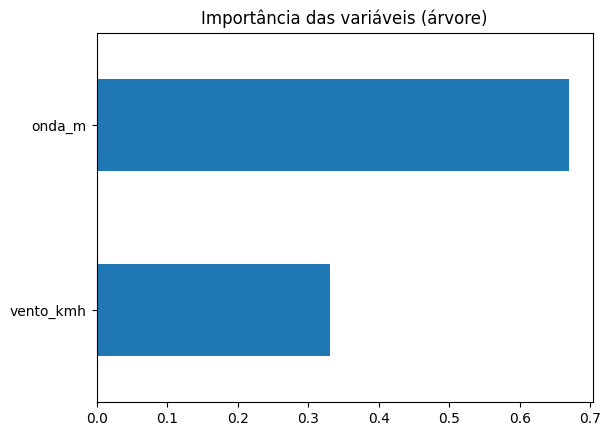

In [12]:
importancia = pd.Series(arvore.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importancia.round(3))

importancia[importancia > 0].sort_values().plot(kind="barh")
plt.title("Importância das variáveis (árvore)")
plt.show()

1. Sim, são praticamente os mesmos. A árvore cortou a onda em 1,15m e em 1,25m, e o vento em 25,5km/h e em 22,5km/h, como a onda só tem valores como 1,1 e 1,2, cortar em 1,15 é o mesmo que 1,2 m ou mais, e cortar em 1,25 é o mesmo que 1,3 m ou mais, o vento é igual, 25,5 equivale a até 25 e 22,5 equivale a até 22. Ou seja, a árvore achou exatamente os meus números (1,2 e 1,3 m, 25 e 22 km/h). Os cortes ficaram no meio entre dois valores só porque é assim que a árvore escolhe.

2. A altura da onda (67%) e o vento (33%), todas as outras (maré, hora e direções) ficaram com importância zero, o que bate com a minha intuição de que onda e vento são protagonistas na questão de definir a qualidade.

3. Porque eu criei a classe usando a onda e o vento, e o modelo recebeu essas duas colunas, o que aconteceu é que ele só descobriu a regra que eu já tinha escrito, e não aprendeu nada novo sobre o mar. A acurácia alta mostra que a árvore copiou bem a minha regra, e não que ela prevê bem as ondas.

## 8. Responder a pergunta

Aplique o modelo na janela inteira e produza a resposta para Felipe e Nicholas:

- Quais os melhores dias da janela de previsão?
- Em média, qual o melhor horário do dia?
- Em que grau essa resposta é uma previsão do mar, e em que grau é apenas a
  sua regra reescrita?

In [13]:
final = DecisionTreeClassifier(max_depth=4, random_state=42)
final.fit(X, y)

df["previsto"] = final.predict(X)
proba = pd.DataFrame(final.predict_proba(X), columns=final.classes_, index=df.index)
df["pontuacao"] = proba["ótima"] + 0.5 * proba["boa"]

ranking = df.sort_values(["pontuacao", "onda_m", "vento_kmh"], ascending=[False, False, True])
ranking[["datetime", "onda_m", "vento_kmh", "previsto", "pontuacao"]].head(10)

,datetime,onda_m,vento_kmh,previsto,pontuacao
134,2026-10-14 14:00:00,1.4,18.0,ótima,1.0
135,2026-10-14 15:00:00,1.4,18.0,ótima,1.0
136,2026-10-14 16:00:00,1.4,18.0,ótima,1.0
137,2026-10-14 17:00:00,1.4,18.0,ótima,1.0
129,2026-10-14 09:00:00,1.4,19.0,ótima,1.0
130,2026-10-14 10:00:00,1.4,19.0,ótima,1.0
131,2026-10-14 11:00:00,1.4,19.0,ótima,1.0
133,2026-10-14 13:00:00,1.4,19.0,ótima,1.0
150,2026-10-15 06:00:00,1.4,19.0,ótima,1.0
151,2026-10-15 07:00:00,1.4,19.0,ótima,1.0


In [14]:
por_dia = df.groupby(df["datetime"].dt.strftime("%d/%m")).agg(
    horas_otimas=("previsto", lambda s: (s == "ótima").sum()),
    horas_boas=("previsto", lambda s: (s == "boa").sum()),
    pontuacao_media=("pontuacao", "mean"),
).round(2).sort_values("pontuacao_media", ascending=False)
print(por_dia)

por_hora = df.groupby("hora")["pontuacao"].mean().round(2).sort_values(ascending=False)
print(por_hora.head(5))

          horas_otimas  horas_boas  pontuacao_media
datetime                                           
15/10               13          11             0.77
14/10               16           5             0.77
12/10                1          22             0.50
13/10                5          10             0.42
11/10                0           0             0.00
09/10                0           0             0.00
10/10                0           0             0.00
hora
16    0.43
17    0.43
15    0.43
14    0.43
12    0.43
Name: pontuacao, dtype: float64


1. Os dias 14 e 15 de outubro, já que os dois ficam empatados na pontuação média (0,77). O dia 14 tem mais horas ótimas (16 contra 13), mas o dia 15 não tem nenhuma hora ruim, tem também o dia 12 (0,50) e o 13 (0,42), mas os dias 9, 10 e 11 têm pontuação zero, porque a onda ficou em torno de 1,0m. 

2. À tarde, entre 12 e 17h, pois é nessa  faixa que a pontuação chega a 0,43, mas a diferença quando comparadas entre horas é mínima geralmente, o que muda mesmo é quando se compara de um dia para o outro, essa faixa que eu citei se destaca devido ao fato de nesse momento o vento ser relativamente mais fraco.

3. É quase só a minha regra, a árvore deu nota máxima a todas as horas que a minha regra chama de ótima, e a ordem entre elas veio do meu desempate (maior onda e menor vento), não do modelo, os dias 14 e 15 aparecem em primeiro porque a previsão do site já traz ondas maiores e vento mais fraco neles. O resultado acaba sendo um resumo da previsão do site segundo a perspectiva que eu montei, e não uma previsão minha do mar.

## 9. Conclusão e limites

Em texto:

1. A recomendação, em uma frase.
2. O teto deste modelo: ele reproduz a sua heurística, então é tão bom quanto
   ela. O que faria dela uma regra melhor?
3. O que a janela de ~7 dias e o volume de linhas impedem de afirmar.
4. Como você responderia "qual a melhor época do ano para surfar em João
   Pessoa" — que dado faltaria, e como coletá-lo.

1. O melhor momento seria o período da tarde do dia 14/10, mas também no dia 15.

2. Provavelmente o que mais fortaleceria a regra e consequentemente o modelo seria se a regra fosse remodulada com o auxílio de um surfista profissional, então o resultado seria muito mais preciso e assertivo com relação com a realidade.

3. Só tenho 7 dias de previsão, e os dados são previsões do site, não medições, além disso 3 dos 7 dias todas as horas foram ruins, então o modelo viu pouca variedade. Por isso não dá para saber se ele funcionaria em outra semana, ou seja, se ele seria assertivo quando exposto a casos que não viu, o que poderia indicar que o modelo ficou "viciado".

4. Não dá para responder com esses dados, porque eles cobrem só uma semana, precisaria de um histórico de ondas e vento de pelo menos um ano. Para conseguir isso, poderia rodar o scraper todo dia e guardar as previsões ou procurar por uma fonte de dados antigos de João Pessoa.